In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
import os
from torch.utils.data import DataLoader


In [2]:
# Set paths for train, test, and validation datasets
train_path = r"D:\deeplearning\vscode deep\Birds_25\train"
test_path = r"D:\deeplearning\vscode deep\Birds_25\test"
validation_path = r"D:\deeplearning\vscode deep\Birds_25\val"
# Define image transformations for training, validation, and test datasets
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),  # Resize images to 224x224 as ResNet expects
        transforms.RandomHorizontalFlip(),  # Data augmentation
        transforms.ToTensor(),  # Convert images to PyTorch tensors
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])  # Normalize with ImageNet statistics
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# Load datasets with ImageFolder
train_dataset = datasets.ImageFolder(root=train_path, transform=data_transforms['train'])
val_dataset = datasets.ImageFolder(root=validation_path, transform=data_transforms['val'])
test_dataset = datasets.ImageFolder(root=test_path, transform=data_transforms['test'])

# Define data loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=4)
 

In [3]:
# Check if GPU is available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Load ResNet-18 model pre-trained on ImageNet
model = models.resnet18(pretrained=True)

# Modify the final layer to match the number of classes in your dataset
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, len(train_dataset.classes))

# Move the model to the GPU
model = model.to(device)


c:\Users\bhore\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\bhore\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [4]:
# Define the loss function
criterion = nn.CrossEntropyLoss()

# Define the optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)


In [5]:
num_epochs = 20

for epoch in range(num_epochs):
    print(f'Epoch {epoch+1}/{num_epochs}')
    print('-' * 10)

    # Training phase
    model.train()
    running_loss = 0.0
    running_corrects = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        # Backward pass + optimize
        loss.backward()
        optimizer.step()

        # Track statistics
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len(train_dataset)
    epoch_acc = running_corrects.double() / len(train_dataset)

    print(f'Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

    # Validation phase
    model.eval()
    val_loss = 0.0
    val_corrects = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            val_corrects += torch.sum(preds == labels.data)

    val_loss = val_loss / len(val_dataset)
    val_acc = val_corrects.double() / len(val_dataset)

    print(f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}')

print('Training complete')


Epoch 1/20
----------
Train Loss: 0.7246 Acc: 0.7827
Val Loss: 0.5039 Acc: 0.8487
Epoch 2/20
----------
Train Loss: 0.3991 Acc: 0.8789
Val Loss: 0.3188 Acc: 0.9031
Epoch 3/20
----------
Train Loss: 0.3168 Acc: 0.9033
Val Loss: 0.3140 Acc: 0.9025
Epoch 4/20
----------
Train Loss: 0.2407 Acc: 0.9249
Val Loss: 0.3168 Acc: 0.9054
Epoch 5/20
----------
Train Loss: 0.2245 Acc: 0.9307
Val Loss: 0.1347 Acc: 0.9555
Epoch 6/20
----------
Train Loss: 0.1894 Acc: 0.9409
Val Loss: 0.1425 Acc: 0.9544
Epoch 7/20
----------
Train Loss: 0.1634 Acc: 0.9505
Val Loss: 0.1353 Acc: 0.9583
Epoch 8/20
----------
Train Loss: 0.1377 Acc: 0.9571
Val Loss: 0.1293 Acc: 0.9609
Epoch 9/20
----------
Train Loss: 0.1301 Acc: 0.9577
Val Loss: 0.1929 Acc: 0.9427
Epoch 10/20
----------
Train Loss: 0.1186 Acc: 0.9628
Val Loss: 0.0737 Acc: 0.9763
Epoch 11/20
----------
Train Loss: 0.1025 Acc: 0.9686
Val Loss: 0.0641 Acc: 0.9818
Epoch 12/20
----------
Train Loss: 0.0899 Acc: 0.9735
Val Loss: 0.0665 Acc: 0.9796
Epoch 13/20
-

Test Loss: 0.2075 Acc: 0.9443


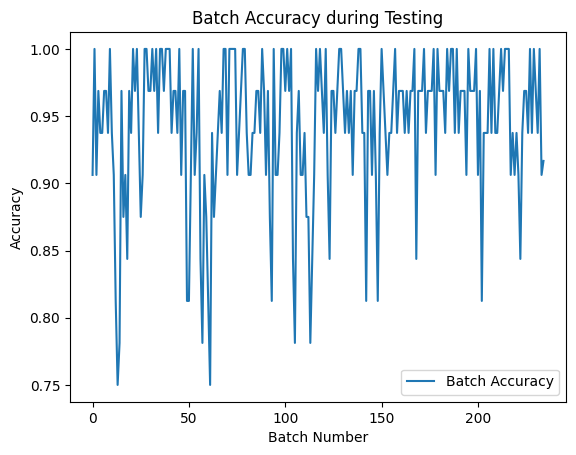

In [6]:
import matplotlib.pyplot as plt

model.eval()
test_loss = 0.0
test_corrects = 0
accuracy_list = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * inputs.size(0)
        test_corrects += torch.sum(preds == labels.data)
        
        # Calculate accuracy for the current batch
        batch_acc = torch.sum(preds == labels.data).double() / inputs.size(0)
        accuracy_list.append(batch_acc.item())

test_loss = test_loss / len(test_dataset)
test_acc = test_corrects.double() / len(test_dataset)

print(f'Test Loss: {test_loss:.4f} Acc: {test_acc:.4f}')

# Plot accuracy chart]
plt.plot(accuracy_list, label='Batch Accuracy')
plt.xlabel('Batch Number')
plt.ylabel('Accuracy')
plt.title('Batch Accuracy during Testing')
plt.legend()
plt.show()


In [7]:
# Save the trained model
torch.save(model.state_dict(), 'resnet18_face_recognition.pth')


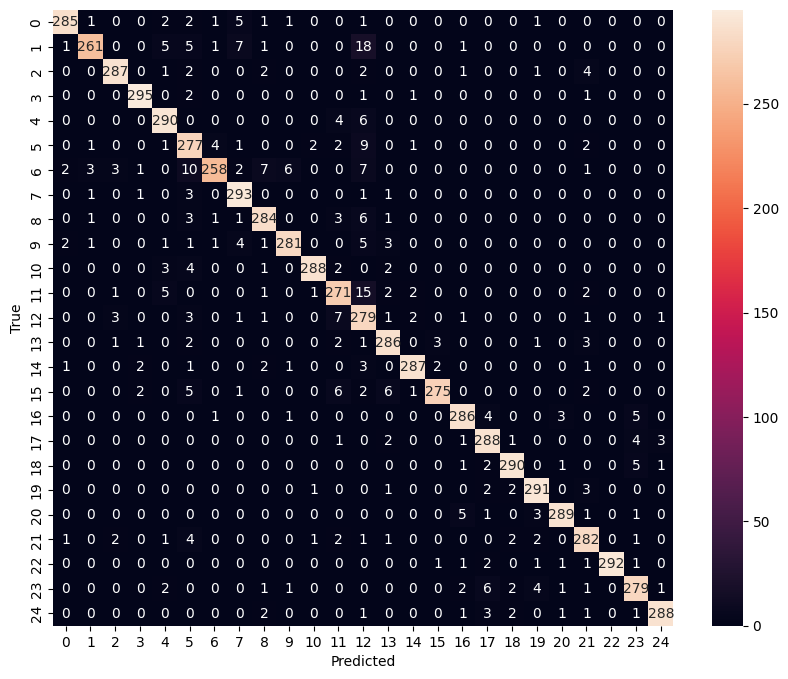

In [8]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute confusion matrix
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


In [9]:
from sklearn.metrics import classification_report

# Collect all predictions and true labels
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Generate classification report
report = classification_report(all_labels, all_preds, target_names=test_dataset.classes)
print(report)


                           precision    recall  f1-score   support

    Asian-Green-Bee-Eater       0.98      0.95      0.96       300
      Brown-Headed-Barbet       0.97      0.87      0.92       300
             Cattle-Egret       0.97      0.96      0.96       300
        Common-Kingfisher       0.98      0.98      0.98       300
              Common-Myna       0.93      0.97      0.95       300
         Common-Rosefinch       0.85      0.92      0.89       300
        Common-Tailorbird       0.97      0.86      0.91       300
       Coppersmith-Barbet       0.93      0.98      0.95       300
           Forest-Wagtail       0.93      0.95      0.94       300
             Gray-Wagtail       0.97      0.94      0.95       300
                   Hoopoe       0.98      0.96      0.97       300
               House-Crow       0.90      0.90      0.90       300
     Indian-Grey-Hornbill       0.78      0.93      0.85       300
           Indian-Peacock       0.93      0.95      0.94     

In [16]:
import torch
from torchviz import make_dot

sample_input = torch.randn(1, 3, 224, 224).to(device)
model_output = model(sample_input)
make_dot(model_output, params=dict(model.named_parameters())).render("resnet18_architecture", format="png")


ExecutableNotFound: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH